# Tugas 1 - Klasifikasi Jamur dengan Naive Bayes

| Nama | NRP |
|------|-----|
| Fahmi Alfayadh | 5054251015|

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Mushroom Dataset dari UCI Machine Learning Repository.

Dataset dapat diakses melalui:
- https://www.kaggle.com/datasets/uciml/mushroom-classification

Untuk metadata / penjelasan mengenai dataset bisa mengakses link berikut:
- https://archive.ics.uci.edu/dataset/73/mushroom

Tujuan utama dari tugas ini adalah membangun dan membandingkan tiga varian Naive Bayes, yaitu Categorical NB, Bernoulli NB, dan Multinomial NB, untuk mengklasifikasikan apakah suatu jamur dapat dimakan (edible) atau beracun (poisonous).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan untuk masing-masing varian Naive Bayes.
3. Eksperimen Model
   - Bangun model Categorical NB, Bernoulli NB, dan Multinomial NB.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [36]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll) 
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split

#naive bayes
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, CategoricalNB
from sklearn.metrics import accuracy_score, recall_score, classification_report, confusion_matrix, roc_auc_score, roc_curve


In [37]:
# Load dataset dan tampilkan beberapa baris pertama.
df = pd.read_csv('dataset/mushrooms.csv')
print(df.head())
print(df.info())
# Semua nilai pada dataset berupa single character yang merupakan kode singkatan dari kategori.
# Contoh: pada kolom class, e = edible dan p = poisonous.

  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w         p          w   
1       

In [38]:
import numpy as np
import pandas as pd

# 1. Tampilkan informasi dasar dataset
print("========= df info() =========")
df.info()  # Langsung panggil tanpa print()

print("\n========= df missing values =========")
print(df.isnull().sum())

# 2. Cek jumlah nilai '?' pada kolom stalk-root
print("\n========= df stalk-root = '?' count =========")
print(f"Jumlah '?': {(df['stalk-root'] == '?').sum()}")

## 2.1 proposi yang ? dengna total
pp = (df['stalk-root'] == '?').sum() / len(df) * 100
print(f"Proposi '?': {pp:.2f}%")


========= df info() =========
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-rin

In [39]:
# 3. Ganti '?' dengan missing value (pd.NA atau np.nan), jadinya ganti "missing" biar orindal encder bisa handle
df['stalk-root'] = df['stalk-root'].replace('?', 'Missing')

# 4. Verifikasi hasil setelah replacement
print("\n========= df stalk-root missing values after replacement =========")
print(f"Jumlah missing value: {df['stalk-root'].isna().sum()}")
print(df['stalk-root'].value_counts(dropna=False))


========= df stalk-root missing values after replacement =========
Jumlah missing value: 0
stalk-root
b          3776
Missing    2480
e          1120
c           556
r           192
Name: count, dtype: int64


In [40]:
# Tampilkan jumlah nilai unik pada setiap fitur.
for column in df.columns:
    unique_values = df[column].nunique()
    print(f"Jumlah nilai unik pada kolom '{column}': {unique_values}")

# Perhatikan variasi jumlah kategori antar fitur, misalnya veil-type hanya punya 1 nilai unik.

Jumlah nilai unik pada kolom 'class': 2
Jumlah nilai unik pada kolom 'cap-shape': 6
Jumlah nilai unik pada kolom 'cap-surface': 4
Jumlah nilai unik pada kolom 'cap-color': 10
Jumlah nilai unik pada kolom 'bruises': 2
Jumlah nilai unik pada kolom 'odor': 9
Jumlah nilai unik pada kolom 'gill-attachment': 2
Jumlah nilai unik pada kolom 'gill-spacing': 2
Jumlah nilai unik pada kolom 'gill-size': 2
Jumlah nilai unik pada kolom 'gill-color': 12
Jumlah nilai unik pada kolom 'stalk-shape': 2
Jumlah nilai unik pada kolom 'stalk-root': 5
Jumlah nilai unik pada kolom 'stalk-surface-above-ring': 4
Jumlah nilai unik pada kolom 'stalk-surface-below-ring': 4
Jumlah nilai unik pada kolom 'stalk-color-above-ring': 9
Jumlah nilai unik pada kolom 'stalk-color-below-ring': 9
Jumlah nilai unik pada kolom 'veil-type': 1
Jumlah nilai unik pada kolom 'veil-color': 4
Jumlah nilai unik pada kolom 'ring-number': 3
Jumlah nilai unik pada kolom 'ring-type': 5
Jumlah nilai unik pada kolom 'spore-print-color': 9
Jum

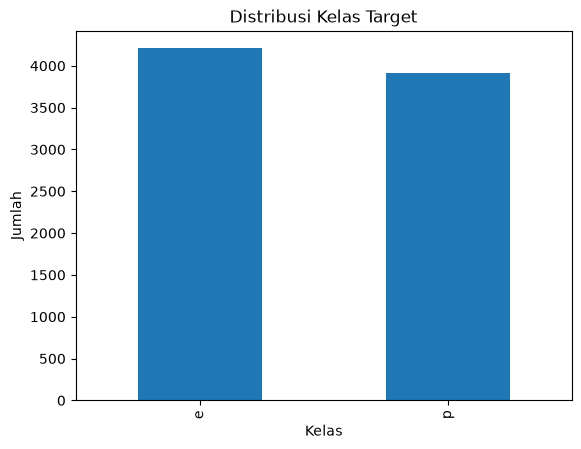


========= df class target distribution =========
Kelas 'e': 4208 (51.80%)
Kelas 'p': 3916 (48.20%)


In [41]:
# Tampilkan distribusi kelas target (class) dalam bentuk bar plot.
df['class'].value_counts().plot(kind='bar')
plt.xlabel('Kelas')
plt.ylabel('Jumlah')
plt.title('Distribusi Kelas Target')
plt.show()

#proposi kelas target
print("\n========= df class target distribution =========")
class_counts = df['class'].value_counts()
total_counts = len(df)
for cls, count in class_counts.items():
    proportion = (count / total_counts) * 100
    print(f"Kelas '{cls}': {count} ({proportion:.2f}%)")
# Perhatikan apakah dataset ini imbalanced.

### dataset balance 
51% edible dan 48% poisonous

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

Karena semua fitur bertipe kategorikal, setiap varian Naive Bayes membutuhkan representasi data yang berbeda:

| Model | Representasi yang dibutuhkan | Preprocessing |
|---|---|---|
| Categorical NB | Integer per kategori | OrdinalEncoder |
| Bernoulli NB | Binary 0/1 per kategori | LabelBinarizer / OneHotEncoder |
| Multinomial NB | Count / frekuensi non-negatif | OneHotEncoder |

In [42]:
# Tangani missing value pada kolom stalk-root (nilai '?').
# Pilih strategi yang sesuai: drop baris, ganti dengan modus, atau jadikan kategori tersendiri.

In [43]:
# Periksa apakah ada fitur yang hanya memiliki satu nilai unik.
for column in df.columns:
    unique_values = df[column].nunique()
    if unique_values == 1:
        print(f"Fitur '{column}' hanya memiliki satu nilai unik dan dapat di-drop.")
# Fitur seperti itu tidak memberikan informasi apapun dan sebaiknya di-drop.

Fitur 'veil-type' hanya memiliki satu nilai unik dan dapat di-drop.


In [44]:
df = df.drop(columns=['veil-type'])  # Drop kolom veil-type karena hanya memiliki satu nilai unik.

In [45]:
df.isnull().sum()  # Periksa kembali apakah masih ada missing value setelah penanganan.

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [46]:
# Pisahkan fitur (X) dan target (y).
x = df.drop(columns=['class'])
y = df['class']
# Encode target: e = 0 (edible), p = 1 (poisonous).
y = y.map({'e': 0, 'p': 1})
# Bagi data menjadi train set dan test set (misalnya 80:20)
# Gunakan train_test_split dari sklearn

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
# Gunakan stratify=y agar distribusi kelas tetap proporsional.


In [47]:
# Preprocessing untuk Categorical NB:

from sklearn.preprocessing import OrdinalEncoder


ordinalencoder = OrdinalEncoder(
)
# Gunakan OrdinalEncoder untuk mengubah setiap kategori menjadi integer.
# Contoh: cap-shape b=0, c=1, f=2, k=3, s=4, x=5
ordinalencoder.fit(x_train)  # Fit hanya pada train set

x_train_ordinal = ordinalencoder.fit_transform(x_train).astype(int)
x_test_ordinal = ordinalencoder.transform(x_test).astype(int)
# Fit hanya pada train set, transform pada train set dan test set.

In [48]:
from sklearn.preprocessing import OneHotEncoder

# Gunakan sparse_output=True untuk versi scikit-learn terbaru
onehotencoder = OneHotEncoder(sparse_output=True, handle_='ignore')

# Fit dan transform sekaligus pada train set
x_train_onehot = onehotencoder.fit_transform(x_train)

# Transform pada test set (menggunakan mapping dari train set)
x_test_onehot = onehotencoder.transform(x_test)

TypeError: OneHotEncoder.__init__() got an unexpected keyword argument 'handle_'

# 3. Eksperimen Model

## 3.1 Categorical Naive Bayes

CategoricalNB adalah varian yang paling sesuai untuk dataset ini karena semua fitur memang bertipe kategorikal. Model menghitung P(fitur=kategori | kelas) secara langsung untuk setiap kategori pada setiap fitur.

In [ ]:
# Inisialisasi dan latih model CategoricalNB menggunakan train set hasil OrdinalEncoder.

from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


categoricalnb = CategoricalNB()
categoricalnb.fit(x_train_ordinal, y_train)


,"alpha alpha: float, default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"min_categories min_categories: int or array-like of shape (n_features,), default=NoneMinimum number of categories per feature.- integer: Sets the minimum number of categories per feature to `n_categories` for each features.- array-like: shape (n_features,) where `n_categories[i]` holds the minimum number of categories for the ith column of the input.- None (default): Determines the number of categories automatically from the training data... versionadded:: 0.24",None
Name,Type,Value
"category_count_ category_count_: list of arrays of shape (n_features,)Holds arrays of shape (n_classes, n_categories of respective feature)for each feature. Each array provides the number of samplesencountered for each class and category of the specific feature.",list,"[array([[ 324.... 0., 1382.]]), array([[1248....134., 1368.]]), array([[ 38.... 542.]]), array([[1161....634., 499.]]), ...]"
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3366.,3133.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.66,-0.73]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_log_prob_ feature_log_prob_: list of arrays of shape (n_features,)Holds arrays of shape (n_classes, n_categories of respective feature)for each feature. Each array provides the empirical log probabilityof categories given the respective feature and class, ``P(x_i|y)``.",list,"[array([[-2.33...-0.81964923]]), array([[-0.99...-0.82918638]]), array([[-4.46...-1.75582372]]), array([[-1.06...-1.83577635]]), ...]"


In [ ]:
# Lakukan prediksi pada test set.
from sklearn.metrics import recall_score

recall_scores = {}
y_pred_categorical = categoricalnb.predict(x_test_ordinal)
recall = recall_score(y_test, y_pred_categorical)
recall_scores['CategoricalNB (Default)'] = recall
print(f"Recall (Kelas 1): {recall:.4f}")

print(classification_report(y_test, y_pred_categorical, digits=4))
print(confusion_matrix(y_test, y_pred_categorical))

y_pred_proba_categorical = categoricalnb.predict_proba(x_test_ordinal)[:, 1]

custom_threshold = 0.35
y_pred_categorical_custom = (y_pred_proba_categorical >= custom_threshold).astype(int)

# 4. Evaluasi menggunakan hasil prediksi threshold baru
recall_custom = recall_score(y_test, y_pred_categorical_custom)
recall_scores['CategoricalNB (Threshold 0.35)'] = recall_custom

print(f"\nThreshold: {custom_threshold}")
print(f"Recall (Kelas 1): {recall_custom:.4f}")
print("\nClassification Report (Custom Threshold):")
print(classification_report(y_test, y_pred_categorical_custom, digits=4))
print("Confusion Matrix (Custom Threshold):")
print(confusion_matrix(y_test, y_pred_categorical_custom))

# 5. Simpan ke DataFrame
hasil_prediksi_categorical = pd.DataFrame({
    'y_true': y_test,
    'y_pred_default': y_pred_categorical,
    'y_pred_custom': y_pred_categorical_custom,
    'y_pred_proba': y_pred_proba_categorical
})


Recall (Kelas 1): 0.8966
              precision    recall  f1-score   support

           0     0.9116    0.9917    0.9499       842
           1     0.9901    0.8966    0.9410       783

    accuracy                         0.9458      1625
   macro avg     0.9508    0.9441    0.9455      1625
weighted avg     0.9494    0.9458    0.9456      1625

[[835   7]
 [ 81 702]]

Threshold: 0.35
Recall (Kelas 1): 0.9195

Classification Report (Custom Threshold):
              precision    recall  f1-score   support

           0     0.9296    0.9881    0.9580       842
           1     0.9863    0.9195    0.9518       783

    accuracy                         0.9551      1625
   macro avg     0.9580    0.9538    0.9549      1625
weighted avg     0.9569    0.9551    0.9550      1625

Confusion Matrix (Custom Threshold):
[[832  10]
 [ 63 720]]


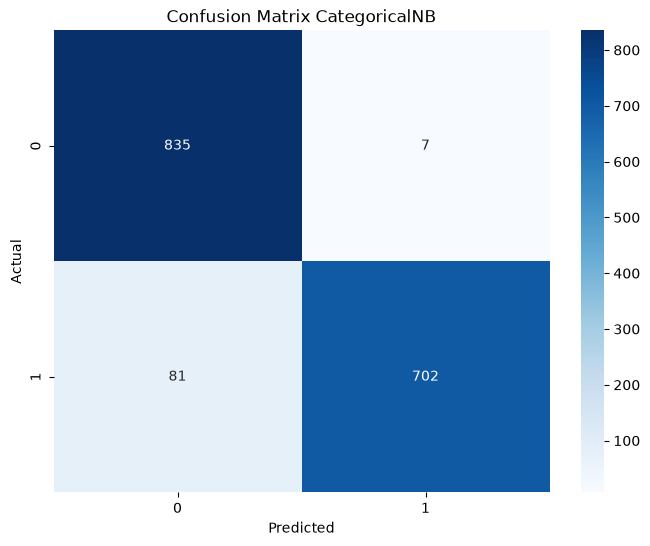


========= Recall Scores =========
CategoricalNB (Default): 0.8966
CategoricalNB (Threshold 0.35): 0.9195


In [ ]:
## recall
import seaborn as sns
import matplotlib.pyplot as plt

# Create a confusion matrix plot
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_categorical), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix CategoricalNB')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print("\n========= Recall Scores =========")
for model, rec in recall_scores.items():
    print(f"{model}: {rec:.4f}")


## 3.2 Bernoulli Naive Bayes

BernoulliNB bekerja pada representasi binary. Dengan OneHotEncoder, setiap kategori menjadi kolom tersendiri bernilai 0 atau 1, sehingga model memperlakukan setiap kategori sebagai fitur binary ada/tidak ada.

In [ ]:
# Inisialisasi dan latih model BernoulliNB menggunakan train set hasil OneHotEncoder.
bernoullinb = BernoulliNB()
bernoullinb.fit(x_train_onehot, y_train)


,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"binarize binarize: float or None, default=0.0Threshold for binarizing (mapping to booleans) of sample features.If None, input is presumed to already consist of binary vectors.",0.0
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3366.,3133.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Log probability of each class (smoothed).","ndarray[float64](2,)","[-0.66,-0.73]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 116)","[[ 324., 0.,1276.,..., 109., 80., 157.], [ 37., 4.,1241.,..., 782., 221., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of features given a class, P(x_i|y).","ndarray[float64](2, 116)","[[-2.34,-8.12,-0.97,...,-3.42,-3.73,-3.06], [-4.41,-6.44,-0.93,...,-1.39,-2.65,-8.05]]"


In [51]:
# Lakukan prediksi pada test set.
y_pred_bernoulli = bernoullinb.predict(x_test_onehot)
recall = recall_score(y_test, y_pred_bernoulli)
recall_scores['BernoulliNB (Default)'] = recall
print(f"Recall (Kelas 1): {recall:.4f}")

print(classification_report(y_test, y_pred_bernoulli))
print(confusion_matrix(y_test, y_pred_bernoulli))

y_pred_proba_bernoulli = bernoullinb.predict_proba(x_test_onehot)[:, 1]

custom_threshold = 0.35
y_pred_bernoulli_custom = (y_pred_proba_bernoulli >= custom_threshold).astype(int)

# 4. Evaluasi menggunakan hasil prediksi threshold baru
recall_custom = recall_score(y_test, y_pred_bernoulli_custom)
recall_scores['BernoulliNB (Threshold 0.35)'] = recall_custom

print(f"\nThreshold: {custom_threshold}")
print(f"Recall (Kelas 1): {recall_custom:.4f}")
print("\nClassification Report (Custom Threshold):")
print(classification_report(y_test, y_pred_bernoulli_custom))
print("Confusion Matrix (Custom Threshold):")
print(confusion_matrix(y_test, y_pred_bernoulli_custom))

# 5. Simpan ke DataFrame
hasil_prediksi_bernoulli = pd.DataFrame({
    'y_true': y_test,
    'y_pred_default': y_pred_bernoulli,
    'y_pred_custom': y_pred_bernoulli_custom,
    'y_pred_proba': y_pred_proba_bernoulli
})


Recall (Kelas 1): 0.8774
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       842
           1       0.98      0.88      0.93       783

    accuracy                           0.93      1625
   macro avg       0.94      0.93      0.93      1625
weighted avg       0.94      0.93      0.93      1625

[[829  13]
 [ 96 687]]

Threshold: 0.35
Recall (Kelas 1): 0.8825

Classification Report (Custom Threshold):
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       842
           1       0.98      0.88      0.93       783

    accuracy                           0.93      1625
   macro avg       0.94      0.93      0.93      1625
weighted avg       0.94      0.93      0.93      1625

Confusion Matrix (Custom Threshold):
[[827  15]
 [ 92 691]]


## 3.3 Multinomial Naive Bayes

MultinomialNB membutuhkan input non-negatif dan menginterpretasikannya sebagai frekuensi. Dengan OneHotEncoder yang menghasilkan nilai 0 dan 1, model dapat menerimanya sebagai counts meskipun secara semantik tiap nilai hanya menandakan ada/tidak ada kategori.

In [ ]:
# Inisialisasi dan latih model MultinomialNB menggunakan train set hasil OneHotEncoder.
ohe = OneHotEncoder(sparse_output=True, handle_unknown='ignore')

x_train_onehot = ohe.fit_transform(x_train)
x_test_onehot = ohe.transform(x_test)

multinomialnb = MultinomialNB()
multinomialnb.fit(x_train_onehot, y_train)


,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3366.,3133.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.66,-0.73]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 116)","[[ 324., 0.,1276.,..., 109., 80., 157.], [ 37., 4.,1241.,..., 782., 221., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 116)","[[ -5.38,-11.17, -4.02,..., -6.47, -6.77, -6.11], [ -7.46, -9.49, -3.97,..., -4.43, -5.69,-11.1 ]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,116


In [54]:
y_pred_multinomial = multinomialnb.predict(x_test_onehot)
recall = recall_score(y_test, y_pred_multinomial)
recall_scores['MultinomialNB (Default)'] = recall
print(f"Recall (Kelas 1): {recall:.4f}")

print(classification_report(y_test, y_pred_multinomial))
print(confusion_matrix(y_test, y_pred_multinomial))

y_pred_proba_multinomial = multinomialnb.predict_proba(x_test_onehot)[:, 1]

custom_threshold = 0.35
y_pred_multinomial_custom = (y_pred_proba_multinomial >= custom_threshold).astype(int)

# 4. Evaluasi menggunakan hasil prediksi threshold baru
recall_custom = recall_score(y_test, y_pred_multinomial_custom)
recall_scores['MultinomialNB (Threshold 0.35)'] = recall_custom

print(f"\nThreshold: {custom_threshold}")
print(f"Recall (Kelas 1): {recall_custom:.4f}")
print("\nClassification Report (Custom Threshold):")
print(classification_report(y_test, y_pred_multinomial_custom))
print("Confusion Matrix (Custom Threshold):")
print(confusion_matrix(y_test, y_pred_multinomial_custom))


Recall (Kelas 1): 0.8966
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       842
           1       0.99      0.90      0.94       783

    accuracy                           0.95      1625
   macro avg       0.95      0.94      0.95      1625
weighted avg       0.95      0.95      0.95      1625

[[835   7]
 [ 81 702]]

Threshold: 0.35
Recall (Kelas 1): 0.9195

Classification Report (Custom Threshold):
              precision    recall  f1-score   support

           0       0.93      0.99      0.96       842
           1       0.99      0.92      0.95       783

    accuracy                           0.96      1625
   macro avg       0.96      0.95      0.95      1625
weighted avg       0.96      0.96      0.95      1625

Confusion Matrix (Custom Threshold):
[[832  10]
 [ 63 720]]


In [55]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
hasil_prediksi_multinomial = pd.DataFrame({
    'y_true': y_test,
    'y_pred_default': y_pred_multinomial,
    'y_pred_custom': y_pred_multinomial_custom,
    'y_pred_proba': y_pred_proba_multinomial
})
hasil_prediksi_multinomial.to_csv('prediksi_multinomial.csv', index=False)


# 4. Evaluasi Model

In [ ]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
print("========= Evaluasi Recall Model (Kelas 1 - Poisonous) =========")
for model, rec in recall_scores.items():
    print(f"{model}: {rec:.4f}")


========= Evaluasi Recall Model (Kelas 1 - Poisonous) =========
CategoricalNB (Default): 0.8966
CategoricalNB (Threshold 0.35): 0.9195
BernoulliNB (Default): 0.8774
BernoulliNB (Threshold 0.35): 0.8825
MultinomialNB (Default): 0.8966
MultinomialNB (Threshold 0.35): 0.9195



========= Perbandingan Metrik Evaluasi (Default Threshold 0.5) =========
CategoricalNB (Default 0.5):
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       842
           1       0.99      0.90      0.94       783

    accuracy                           0.95      1625
   macro avg       0.95      0.94      0.95      1625
weighted avg       0.95      0.95      0.95      1625

BernoulliNB (Default 0.5):
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       842
           1       0.98      0.88      0.93       783

    accuracy                           0.93      1625
   macro avg       0.94      0.93      0.93      1625
weighted avg       0.94      0.93      0.93      1625

MultinomialNB (Default 0.5):
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       842
           1       0.99      0.90      0.94       783

    accuracy           

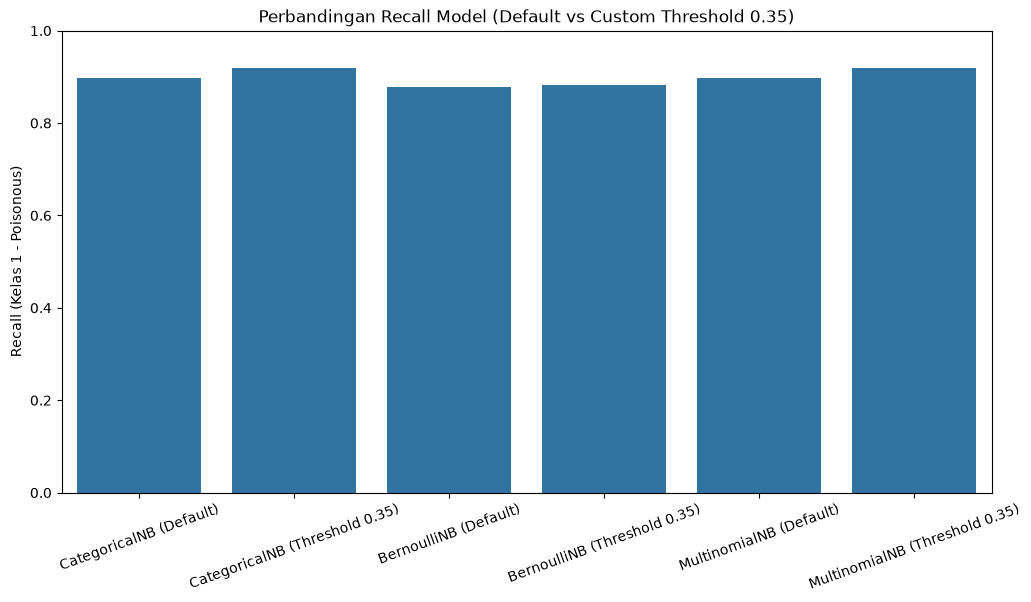

In [56]:
print("\n========= Perbandingan Metrik Evaluasi (Default Threshold 0.5) =========")
print("CategoricalNB (Default 0.5):")
print(classification_report(y_test, y_pred_categorical))

print("BernoulliNB (Default 0.5):")
print(classification_report(y_test, y_pred_bernoulli))

print("MultinomialNB (Default 0.5):")
print(classification_report(y_test, y_pred_multinomial))

print("\n========= Perbandingan Metrik Evaluasi (Custom Threshold 0.35) =========")
print("CategoricalNB (Threshold 0.35):")
print(classification_report(y_test, y_pred_categorical_custom))

print("BernoulliNB (Threshold 0.35):")
print(classification_report(y_test, y_pred_bernoulli_custom))

print("MultinomialNB (Threshold 0.35):")
print(classification_report(y_test, y_pred_multinomial_custom))

plt.figure(figsize=(12, 6))
sns.barplot(x=list(recall_scores.keys()), y=list(recall_scores.values()))
plt.title('Perbandingan Recall Model (Default vs Custom Threshold 0.35)')
plt.ylabel('Recall (Kelas 1 - Poisonous)')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()


In [57]:
print(recall_scores)

{'CategoricalNB (Default)': 0.896551724137931, 'CategoricalNB (Threshold 0.35)': 0.9195402298850575, 'BernoulliNB (Default)': 0.8773946360153256, 'BernoulliNB (Threshold 0.35)': 0.8825031928480205, 'MultinomialNB (Default)': 0.896551724137931, 'MultinomialNB (Threshold 0.35)': 0.9195402298850575}



========= Confusion Matrix CategoricalNB (Default 0.5) ================


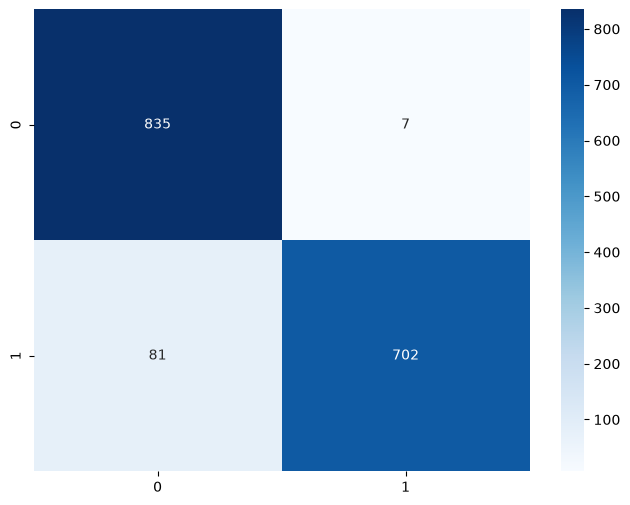

recall CategoricalNB (Default 0.5): 0.8966

============ Confusion Matrix CategoricalNB (Threshold 0.35) ====================


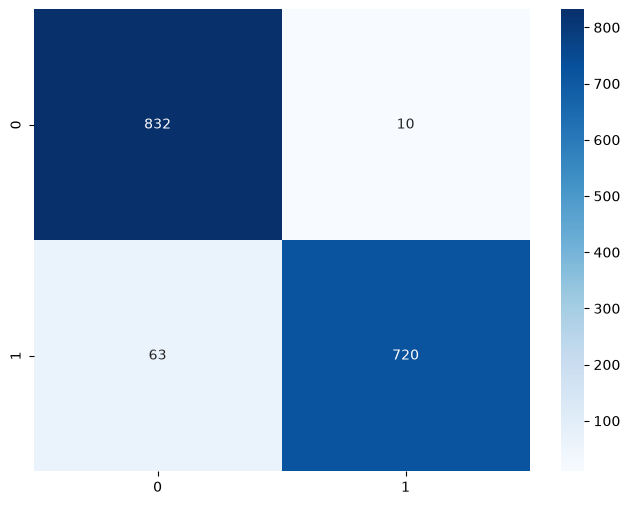

recall CategoricalNB (Threshold 0.35): 0.9195

============ Confusion Matrix BernoulliNB (Default 0.5) =====================


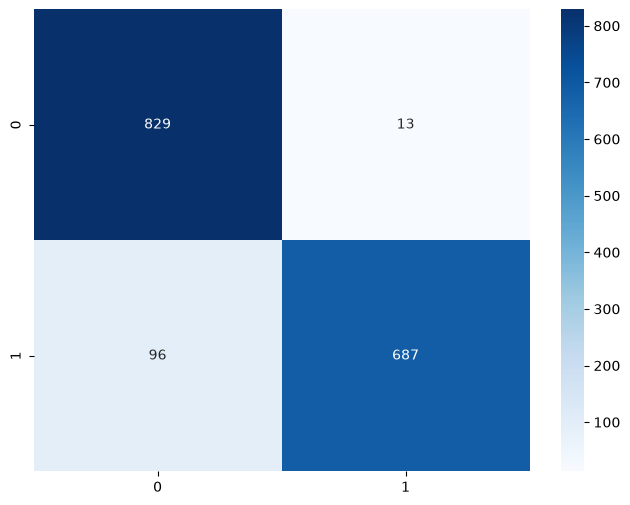

recall BernoulliNB (Default 0.5): 0.8774

========= Confusion Matrix BernoulliNB (Threshold 0.35) =========


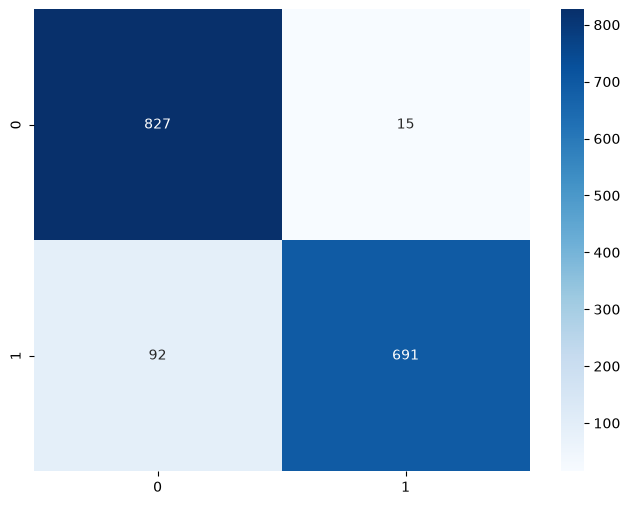

recall BernoulliNB (Threshold 0.35): 0.8825

========= Confusion Matrix MultinomialNB (Default) =========


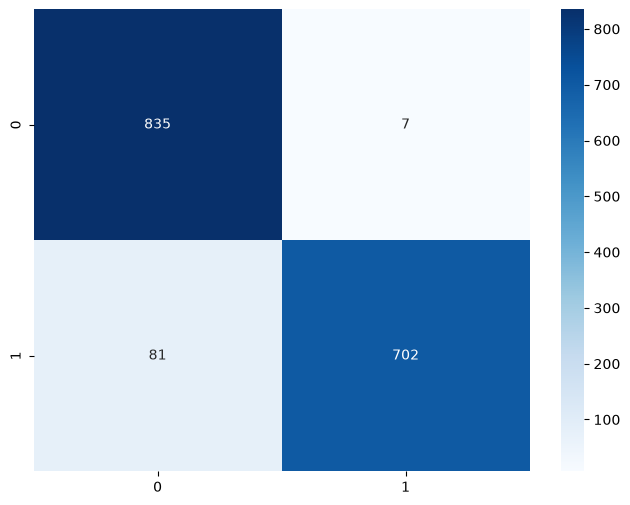

recall MultinomialNB (Default 0.5): 0.8966

========= Confusion Matrix MultinomialNB (Threshold 0.35) =========


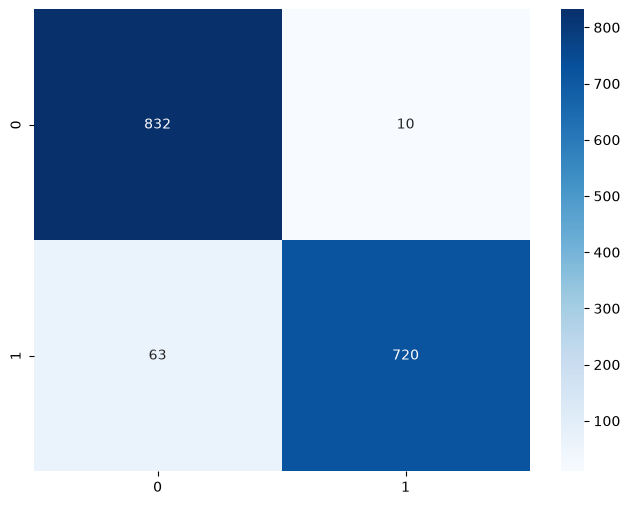

recall MultinomialNB (Threshold 0.35): 0.9195


In [60]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.

print("\n========= Confusion Matrix CategoricalNB (Default 0.5) ================")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_categorical), annot=True, fmt='d', cmap='Blues')
plt.show()
print(f"recall CategoricalNB (Default 0.5): {recall_scores['CategoricalNB (Default)']:.4f}")

print("\n============ Confusion Matrix CategoricalNB (Threshold 0.35) ====================")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_categorical_custom), annot=True, fmt='d', cmap='Blues')
plt.show()
print(f"recall CategoricalNB (Threshold 0.35): {recall_scores['CategoricalNB (Threshold 0.35)']:.4f}")

print("\n============ Confusion Matrix BernoulliNB (Default 0.5) =====================")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_bernoulli), annot=True, fmt='d', cmap='Blues')
plt.show()
print(f"recall BernoulliNB (Default 0.5): {recall_scores['BernoulliNB (Default)']:.4f}")

print("\n========= Confusion Matrix BernoulliNB (Threshold 0.35) =========")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_bernoulli_custom), annot=True, fmt='d', cmap='Blues')
plt.show()
print(f"recall BernoulliNB (Threshold 0.35): {recall_scores['BernoulliNB (Threshold 0.35)']:.4f}")


print("\n========= Confusion Matrix MultinomialNB (Default) =========")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_multinomial), annot=True, fmt='d', cmap='Blues')
plt.show()
print(f"recall MultinomialNB (Default 0.5): {recall_scores['MultinomialNB (Default)']:.4f}")

print("\n========= Confusion Matrix MultinomialNB (Threshold 0.35) =========")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_multinomial_custom), annot=True, fmt='d', cmap='Blues')
plt.show()
print(f"recall MultinomialNB (Threshold 0.35): {recall_scores['MultinomialNB (Threshold 0.35)']:.4f}")


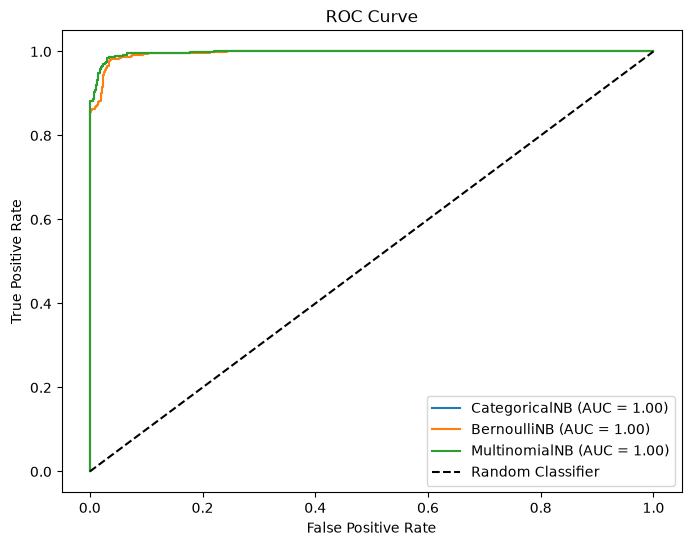

In [ ]:
# Tampilkan ROC Curve ketiga model dalam satu plot beserta nilai AUC masing-masing.
from sklearn.metrics import roc_auc_score, roc_curve

plt.figure(figsize=(8, 6))

# CategoricalNB
fpr, tpr, _ = roc_curve(y_test, y_pred_proba_categorical)
auc = roc_auc_score(y_test, y_pred_proba_categorical)
plt.plot(fpr, tpr, label=f'CategoricalNB (AUC = {auc:.2f})')

# BernoulliNB
fpr, tpr, _ = roc_curve(y_test, y_pred_proba_bernoulli)
auc = roc_auc_score(y_test, y_pred_proba_bernoulli)
plt.plot(fpr, tpr, label=f'BernoulliNB (AUC = {auc:.2f})')

# MultinomialNB
fpr, tpr, _ = roc_curve(y_test, y_pred_proba_multinomial)
auc = roc_auc_score(y_test, y_pred_proba_multinomial)
plt.plot(fpr, tpr, label=f'MultinomialNB (AUC = {auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


# 5. Analisis

### 5.1 Perbandingan Kinerja Model (Fokus pada Metrik Recall)

Pada dataset klasifikasi jamur, metrik **Recall (Kelas 1 - Poisonous)** menjadi parameter evaluasi paling vital guna mencegah jamur beracun salah terprediksi sebagai jamur yang aman dikonsumsi (*False Negative*).

Hasil evaluasi performa ketiga varian Naive Bayes pada data uji (1625 sampel) dengan threshold default (0.5) dan custom threshold (0.35):

| Model | Threshold | Recall (1) | FN | TP | Precision (1) | F1-Score (1) | Akurasi | ROC-AUC |
|---|---|---|---|---|---|---|---|---|
| **CategoricalNB** | 0.5 (Default) | 89.66% | 81 | 702 | 0.99 | 0.94 | 94.58% | 1.00 |
| **CategoricalNB** | 0.35 (Custom) | 91.95% | 63 | 720 | 0.99 | 0.95 | 95.51% | 1.00 |
| **BernoulliNB** | 0.5 (Default) | 87.74% | 96 | 687 | 0.98 | 0.93 | 93.29% | 1.00 |
| **BernoulliNB** | 0.35 (Custom) | 88.25% | 92 | 691 | 0.98 | 0.93 | 93.42% | 1.00 |
| **MultinomialNB** | 0.5 (Default) | 89.66% | 81 | 702 | 0.99 | 0.94 | 94.58% | 1.00 |
| **MultinomialNB** | 0.35 (Custom) | 91.95% | 63 | 720 | 0.99 | 0.95 | 95.51% | 1.00 |

*Catatan: Kelas 0 = edible (842 sampel), Kelas 1 = poisonous (783 sampel).*

### 5.2 Dampak Custom Threshold (0.35) terhadap Penurunan False Negative

1. **Penurunan False Negative Signifikan**
   - Menurunkan threshold dari 0.5 ke 0.35 membuat model lebih berhati-hati dalam menetapkan jamur sebagai edible.
   - Pada CategoricalNB dan MultinomialNB, False Negative berkurang dari 81 menjadi 63 kasus (18 jamur beracun berhasil diselamatkan dari salah konsumsi). Recall meningkat dari 89.66% ke **91.95%**, dan akurasi turut naik dari 94.58% ke **95.51%**.
   - Pada BernoulliNB, False Negative berkurang dari 96 menjadi 92 kasus, dengan Recall naik dari 87.74% ke 88.25%.

2. **Rasionalisasi Metrik dalam Konteks Keracunan Jamur**
   - Mengonsumsi jamur beracun karena salah label (*False Negative*) berakibat fatal.
   - Sementara itu, False Positive hanya bertambah 3 sampel (dari 7 menjadi 10 pada CategoricalNB/MultinomialNB). Kenaikan False Positive yang sangat kecil ini sangat sepadan demi mendapatkan penurunan 18 kasus False Negative.

### 5.3 Hubungan Representasi Data dengan Performa Model

- **CategoricalNB vs MultinomialNB**: Menghasilkan kinerja yang sama persis di seluruh threshold (Recall 91.95% pada threshold 0.35). Karena setiap sampel memiliki 21 fitur kategorikal aktif konstan pada matriks One-Hot, pembobotan frekuensi MultinomialNB setara dengan probabilitas kategori CategoricalNB.
- **BernoulliNB**: Menghasilkan Recall lebih rendah (88.25% vs 91.95%) karena BernoulliNB memperhitungkan ketiadaan kategori (nilai 0 pada matriks biner) secara independen, yang memberikan penalti berlebih pada data berdimensi jarang (*sparse*).

# 6. Kesimpulan

### 6. Kesimpulan

1. Metrik Recall pada kelas 1 (poisonous) saya jadikan merupakan prioritas dalam klasifikasi jamur untuk menghindari risiko fatal akibat jamur beracun yang salah terprediksi sebagai edible (*False Negative*).
2. Penerapan custom threshold 0.35 berhasil meningkatkan Recall CategoricalNB dan MultinomialNB menjadi **91.95%** (naik dari 89.66%) dan memangkas 18 kasus False Negative (dari 81 menjadi 63 kasus).
3. CategoricalNB dan MultinomialNB memiliki performa identik dan lebih unggul dibandingkan BernoulliNB di semua ambang batas, baik dari segi Recall (91.95% vs 88.25%), Akurasi (95.51% vs 93.42%), maupun ROC-AUC (1.00).
4. Penurunan threshold ke 0.35 memberikan trade-off yang sangat optimal: menurunkan False Negative sebanyak 18 sampel dengan hanya menambah 3 sampel False Positive.